# BERT

In this notebook, the candidates are ranked based on their similarity to the target job title.

A BERT model is used to convert the words into embeddings.

The similarity is the assessed using different vector comparison methods - cosine, dot product, manhattan and euclidean.

The similarities are turned into rankings and compared to the manual scores assigned to the candidates.

In [1]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nltk.stem import PorterStemmer
import torch
from transformers import AutoTokenizer, AutoModel, AutoModelForMaskedLM, DataCollatorForLanguageModeling
from datasets import Dataset
import torch.nn.functional as F
from sklearn.model_selection import train_test_split

In [2]:
# import the cleaned data from CSV file
data = pd.read_csv('../data/potential_talents_cleaned.csv')

In [3]:
# use basic pre-trained BERT model
model_name = "google-bert/bert-base-uncased"
# load the BERT tokeniser
tokenizer = AutoTokenizer.from_pretrained(model_name)
# load the pre-trained BERT model
model = AutoModel.from_pretrained(model_name)
# put the model in evaluation mode
model.eval()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

In [4]:
# create a function to turn text into embeddings using the model
def get_sentence_embeddings(texts):

    # the tokeniser to turn the text into tokens in the the form of PyTorch tensors
    inputs = tokenizer(
    texts,
    return_tensors="pt",
    padding=True,
    truncation=True
    )

    # don't train the model, only use it to turn the tokens into contextual embeddings for each token
    with torch.no_grad():
        outputs=model(**inputs)
    token_embeddings = outputs.last_hidden_state

    # create a mask that removes unwanted tokens (start, end, pad etc.)
    attention_mask = inputs['attention_mask']
    special_tokens_mask = torch.tensor([
        tokenizer.get_special_tokens_mask(
            ids.tolist(),
            already_has_special_tokens=True
        )
        for ids in inputs['input_ids']
    ])

    mask = attention_mask * (1 - special_tokens_mask)
    mask = mask.unsqueeze(-1)

    # pool embeddings into a single embedding for each job title, rather than each token
    sentence_embeddings = (
        (token_embeddings * mask).sum(dim=1)
        / mask.sum(dim=1).clamp(min=1)
    )

    return sentence_embeddings

In [5]:
# use funtion to create embeddings for the target and each candidate
target_title = "aspiring hr"
target_embeddings = get_sentence_embeddings([target_title])

candidate_titles = data['job_title'].to_list()
candidate_embeddings = get_sentence_embeddings(candidate_titles)

In [6]:
# assses the similarity of each candidate to the target using 4 different methods
cosine_similarity = F.cosine_similarity(
    target_embeddings,
    candidate_embeddings
)

dot_similarity = torch.matmul(
    target_embeddings, 
    candidate_embeddings.T
).squeeze(0)

euclidean_similarity = torch.cdist(
    target_embeddings,
    candidate_embeddings,
    p=2
).squeeze(0)

manhattan_similarity = torch.cdist(
    target_embeddings,
    candidate_embeddings,
    p=1
).squeeze(0)

In [7]:
# turn the similarity scores into ranks, sort by the cosine rank and show all ranks next to each other
data['cosine_rank'] = pd.Series(cosine_similarity.numpy(), index=data.index).rank(ascending=False, method='min').astype(int)
data['dot_rank'] = pd.Series(dot_similarity.numpy(), index=data.index).rank(ascending=False, method='min').astype(int)
data['euclidean_rank'] = pd.Series(euclidean_similarity.numpy(), index=data.index).rank(ascending=True, method='min').astype(int)
data['manhattan_rank'] = pd.Series(manhattan_similarity.numpy(), index=data.index).rank(ascending=True, method='min').astype(int)
data = data.sort_values(by='cosine_rank', ascending=True).reset_index(drop=True)

In [8]:
# display each candidates job title and 4 similarity ranks
data[['job_title', 'manual_score', 'cosine_rank', 'dot_rank', 'euclidean_rank', 'manhattan_rank']]

,job_title,manual_score,cosine_rank,dot_rank,euclidean_rank,manhattan_rank
0,aspiring hr specialist,5,1,1,1,1
1,aspiring hr professional,5,2,2,2,2
2,aspiring hr professional,5,2,2,2,2
3,hr professional,4,4,4,5,7
4,aspiring hr manager seeking internship in hr,5,5,9,4,4
5,hr senior specialist,4,6,7,7,9
6,hr management major,5,7,6,11,11
7,business management major and aspiring hr manager,5,8,8,8,6
8,aspiring hr management student seeking an inte...,5,9,10,6,5
9,experienced retail manager and aspiring hr pro...,5,10,11,9,8


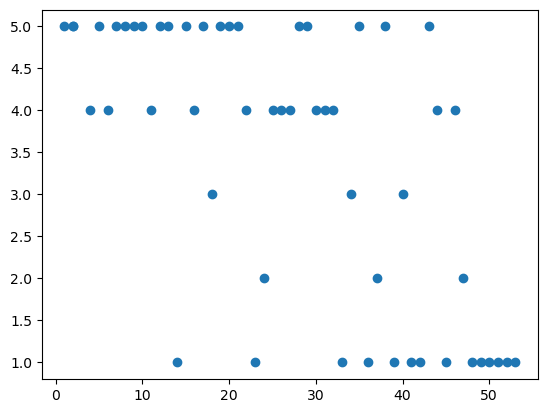

In [9]:
data = data.sort_values(by='cosine_rank', ascending=True)

x = data['cosine_rank']
y = data['manual_score']

plt.scatter(x, y)